# PETSIRD list mode: a Siemens Biograph mMR scan

PETSIRD is the open list-mode format of the Emission Tomography Standardization Initiative ([ETSI](https://etsinitiative.org/)): one file holds a PET scanner's geometry, its normalisation and the coincidences it recorded. This tutorial reconstructs a real scan stored in it: a 60-minute F-18 NEMA image quality phantom acquisition on a Siemens Biograph mMR at University College London (Thomas and Sanderson, Zenodo 1304454), converted to PETSIRD 0.9.1 with ETSI's STIR2PETSIRD.

PyTomography first converts the file to its standard PET form, the same form its GATE and GE readers give. From there the scan is reconstructed like any other PET data: list-mode OSEM with attenuation, normalisation and randoms, first without and then with scatter correction.

Reading PETSIRD needs ETSI's `petsird` package, version 0.9: `pip install "pytomography[petsird]"`.

In [1]:
from pytomography import datasets

# The tutorial data: downloaded the first time it runs (see Tutorial data in the docs)
datasets.fetch("PET/PETSIRD-mMR-NEMA")
DATA = datasets.data_dir()  # the PYTOMOGRAPHY_DATA folder, or ~/pytomography_data
# Results go here, never into the data folder
OUTPUT = datasets.output_dir("PET/PETSIRD-mMR-NEMA")

PET/PETSIRD-mMR-NEMA: already downloaded


In [2]:
import time
import numpy as np
import torch
import matplotlib.pyplot as plt
import pytomography
from pytomography import io
from pytomography.metadata import ObjectMeta
from pytomography.metadata.PET import PETLMProjMeta
from pytomography.projectors.PET import PETLMSystemMatrix
from pytomography.transforms.shared import GaussianFilter
from pytomography.likelihoods import PoissonLogLikelihood
from pytomography.algorithms import OSEM
from pytomography.utils import sss

In [3]:
# Memory: the scan's header holds 2.9 GB of normalisation tables, and the weights of the scanner's 520 million crystal
# pairs take 2.1 GB. RAM_GB caps what the steps that go through every crystal pair (the sensitivity image, the scatter
# estimate) use at once: with less, they work in smaller blocks, which is slower and gives the same images. Each
# reconstruction prints its own estimate before it runs (estimate_memory), with what more subsets would need, and so
# does the scatter estimate (its estimate is on the safe side). MINUTES is how much of the 60-minute scan is
# reconstructed: all of it, 197 million prompts, peaks at 25.2 GB of RAM and 6 GB of GPU memory, in the scatter
# estimate (measured on Windows with PyTorch 2.14; it was 23.4 GB with PyTorch 2.9: PyTorch 2.14 sets aside about
# 3 GB more as soon as it is imported, most of which it never fills). Lowering RAM_GB saves little, since most of
# the peak is the scanner's normalisation and the scatter estimate's sinograms, whatever the scan's length; to use
# less, lower MINUTES: the first 10 minutes (38 million prompts) take about 4 GB less RAM and 2.6 GB of GPU memory.
RAM_GB = 25
pytomography.set_memory_budget(RAM_GB)
MINUTES = 60

## 1. The scan in PyTomography's standard form

PETSIRD 0.9 says neither which way its gantry axes point nor how the patient lies, so `io.PET.read_petsird` takes them as arguments. STIR2PETSIRD writes x pointing up and z pointing out of the gantry towards the bed, and the Siemens headers say the phantom went in head first, supine (HFS). The scanner's `info` then describes it as the GATE and GE readers do (rings, crystals, their spacings, the radius, the energy window), and the images come out in the patient's coordinates: DICOM's LPS, with x to the patient's left, y posterior and z superior. A transverse slice shown as `image[:, :, k].T` has the bed, and the phantom's flat side, at the bottom.

The header is read once and handed on (`header=`): for this scanner it holds 2.9 GB of normalisation tables. The events come out as pairs of PyTomography's crystal numbers, and the normalisation as one weight per pair of crystals (`proj_meta.weights_sensitivity`). The first call in a new Python environment compiles PyTomography's event reader, which takes about 10 s.

In [4]:
path = DATA / 'PET' / 'PETSIRD-mMR-NEMA' / 'mMR_NEMA_norm.petsird'
t0 = time.time()
header = io.PET.petsird.read_header(path)
window_s = (0, MINUTES * 60)  # the time blocks that start in the first MINUTES minutes
# The image grid: the scanner's own voxel size, 200 x 200 x 127 voxels (mm), centred on the scanner (section 2)
prompts, object_meta, proj_meta = io.PET.read_petsird(
    path, object_meta=ObjectMeta(dr=(2.08626, 2.08626, 2.03125), shape=(200, 200, 127)),
    up='+x', towards_bed='+z', patient_position='HFS', time_interval=window_s, header=header)
delayeds, _, _ = io.PET.read_petsird(path, events='delayeds', up='+x', towards_bed='+z', patient_position='HFS',
                                     time_interval=window_s, header=header)
del header  # everything needed from it is now in the events and proj_meta
info = proj_meta.info
weights = proj_meta.weights_sensitivity  # one per crystal pair, in torch.combinations order
print(f"{info['NrRings']} rings of {info['NrCrystalsPerRing']} crystals, radius {info['radius']:.1f} mm, energy window "
      f"{info['energy_window_low']:.0f} to {info['energy_window_high']:.0f} keV")
print(f"first {MINUTES} min: {len(prompts):,} prompts and {len(delayeds):,} delayed coincidences; weights of "
      f"{len(weights):,} crystal pairs; read in {time.time() - t0:.0f} s")

64 rings of 504 crystals, radius 331.5 mm, energy window 430 to 610 keV
first 60 min: 196,574,421 prompts and 20,708,661 delayed coincidences; weights of 520,208,640 crystal pairs; read in 27 s


## 2. The image grid and the attenuation map

The image has the scanner's own voxel size: 200 × 200 × 127 voxels of 2.086 × 2.086 × 2.031 mm, centred on the scanner, with its axes along the patient's. Events whose line of response misses this box are dropped.

The attenuation map comes from the source record: a Siemens Interfile image (`.v.hdr`) of 344 × 344 × 127 voxels of the same size, in 1/cm, centred on the scanner and already in the patient's LPS axes. `io.attenuation_map` reads it with its geometry and units and puts it on the grid, in 1/mm (at 511 keV for a PET grid). The file's crystals sit 0.353° away from where PyTomography's description of the scanner puts its modules (STIR2PETSIRD places each crystal by its corner, half a crystal off); `read_petsird` turns the description of the scanner by that angle (`info['rsector0_angle']`), so the grid's axes are exactly LPS and nothing is resampled by hand.

In [5]:
# Keep the events whose line of response crosses the image
prompts = io.PET.remove_events_outside(prompts, info, object_meta)
n_events = len(prompts)
print(f"{n_events:,} prompts cross the image")

# The scan's attenuation map (Siemens Interfile, 1/cm) on the grid, in 1/mm
folder = DATA / 'PET' / 'PETSIRD-mMR-NEMA'
attenuation_map = io.attenuation_map(folder / '20170809_NEMA_MUMAP_UCL.v.hdr', object_meta)
mu_map = attenuation_map.cpu().numpy()  # for the figures

193,890,571 prompts cross the image


## 3. The system matrix and the randoms

The system matrix projects along each event's line of response, with a 4 mm Gaussian for the scanner's resolution, attenuation from the map, and the normalisation weights. Its sensitivity image goes through all 520 million crystal pairs, a block at a time.

The delayed coincidences estimate the randoms: they are binned into a sinogram, smoothed, and read back on each event's crystal pair. The likelihood takes the randoms divided by each event's sensitivity (its normalisation weight times its attenuation).

In [6]:
t0 = time.time()
proj_meta = PETLMProjMeta(prompts, info, weights_sensitivity=weights)  # the prompts that cross the image
system_matrix = PETLMSystemMatrix(object_meta, proj_meta, obj2obj_transforms=[GaussianFilter(4.0)],
                                  attenuation_map=attenuation_map, N_splits=4)
del prompts  # the system matrix holds the events now
print(f"system matrix and sensitivity image: {time.time() - t0:.0f} s")

t0 = time.time()
sinogram_delays = io.PET.listmode_to_sinogram(delayeds, info)
del delayeds
sinogram_delays = io.PET.smooth_randoms_sinogram(sinogram_delays, info, fwhm_r=20, fwhm_theta=7, fwhm_z=40)
# Per event, on the GPU and with no copies: its sensitivity (normalisation weight times attenuation), and its randoms
# divided by it
lm_sensitivity = system_matrix._compute_sensitivity_projection(all_ids=False).to(pytomography.device)
randoms_term = io.PET.sinogram_to_listmode(proj_meta.detector_ids, sinogram_delays, info).to(pytomography.device)
randoms_term /= lm_sensitivity
randoms_term[randoms_term.isnan()] = 0
print(f"randoms: {time.time() - t0:.0f} s")

system matrix and sensitivity image: 16 s


randoms: 17 s


## 4. Reconstruction without scatter correction

OSEM with 3 iterations of 21 subsets. `estimate_memory` gives the reconstruction's peak RAM and GPU memory before it runs, what they are made of, and what other settings would need.

In [7]:
likelihood = PoissonLogLikelihood(system_matrix, additive_term=randoms_term)
print(system_matrix.estimate_memory(n_subsets=21, held={'additive term': likelihood.additive_term}))
t0 = time.time()
recon_without_scatter = OSEM(likelihood)(n_iters=3, n_subsets=21)
seconds_without = time.time() - t0
print(f"OSEM without scatter correction: {seconds_without:.1f} s")

PETLMSystemMatrix: 21 subsets, memory budget 25 GB
Peak ~ 16.8 GB RAM, 7.4 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 2.1 GB RAM, 3.6 GB GPU (events and their projector order 2.3 GPU, sensitivity weights 2.1 RAM, sensitivity and normalisation images (21) 0.4 GPU, image, update and attenuation map 0.1 GPU, additive term 0.8 GPU)
  one subset at a time: 0.00 GB RAM, 1.2 GB GPU (expected counts, ratio and temporaries (one subset) 0.1 GPU, positions of the subset's events 0.1 GPU, building a subset's projector order (its first projection) 1.0 GPU)
  projector chunks: 0.00 GB RAM, 0.1 GB GPU (projector chunk 0.1 GPU)
  Python, CUDA, allocator: 7.3 GB RAM, 2.4 GB GPU (Python, PyTorch and CUDA 3.0 RAM, CUDA context and libraries on the GPU (outside PyTorch) 0.7 GPU, PyTorch's GPU cache (rounded and kept blocks) 1.8 GPU, memory the allocators keep (Windows) 4.2 RAM)
To use less: 42 subsets ~ 16.8 GB RAM, 7.5 GB GPU, N_splits 8 ~ 16.7 GB RAM, 7.3 GB GPU
(plus wh

OSEM without scatter correction: 15.9 s


The phantom's regions come with the dataset, in its folder: `petsird_mmr_nema_rois.seg.nrrd`, a 3D Slicer segmentation of the phantom in the attenuation map, its six spheres (`sphere_37mm` to `sphere_10mm`, fitted to a reconstruction of this scan) and its background. `io.load_mask` reads it with its place in the scanner, and `.on(object_meta, label=...)` puts each region on the grid; `threshold=0.5` keeps the voxels at least half inside it.

The figures look through the plane of the spheres and through the largest sphere. The red line is the outline of the phantom in the attenuation map: it lines up with the phantom. The phantom's flat side lies on the bed, at the bottom of the transverse view.

In [8]:
# The phantom and its largest sphere, through whose centre the figures look
regions = io.load_mask(folder / 'petsird_mmr_nema_rois.seg.nrrd')
body = regions.on(object_meta, label='phantom', threshold=0.5).cpu().numpy()
sphere = regions.on(object_meta, label='sphere_37mm', threshold=0.5).cpu().numpy()
i, j, k = np.argwhere(sphere).mean(axis=0).round().astype(int)
dx, dy, dz = object_meta.dr
# The phantom's extent with a margin, for the figures
xs, ys, zs = np.nonzero(body)
x0, x1 = max(xs.min() - 4, 0), min(xs.max() + 5, body.shape[0])
y0, y1 = max(ys.min() - 4, 0), min(ys.max() + 5, body.shape[1])
z0, z1 = max(zs.min() - 3, 0), min(zs.max() + 4, body.shape[2])
print(f"centre of the 37 mm sphere: voxel ({i}, {j}, {k})")

centre of the 37 mm sphere: voxel (87, 81, 54)


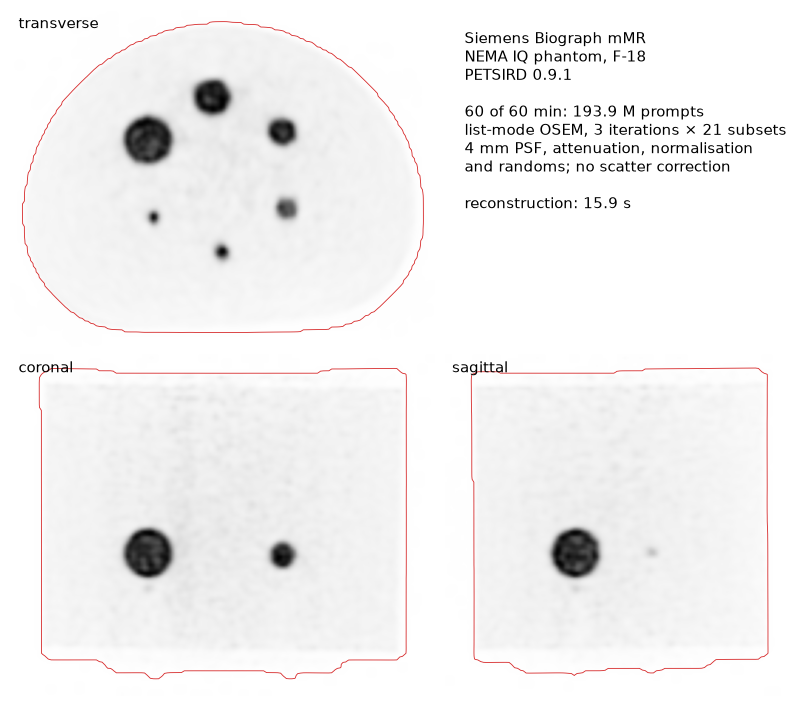

In [9]:
image = recon_without_scatter.cpu().numpy()
vmax = np.percentile(image[:, :, k][body[:, :, k]], 99.9)
phantom_mu = np.where(body, mu_map, 0)  # the attenuation map of the phantom alone, for its outline
views = [  # image, the phantom in the attenuation map, pixel aspect, origin, name
    (image[x0:x1, y0:y1, k].T, phantom_mu[x0:x1, y0:y1, k].T, dy / dx, 'upper', 'transverse'),
    (image[x0:x1, j, z0:z1].T, phantom_mu[x0:x1, j, z0:z1].T, dz / dx, 'lower', 'coronal'),
    (image[i, y0:y1, z0:z1].T, phantom_mu[i, y0:y1, z0:z1].T, dz / dy, 'lower', 'sagittal'),
]
widths, heights = [(x1 - x0) * dx, (y1 - y0) * dy], [(y1 - y0) * dy, (z1 - z0) * dz]
fig = plt.figure(figsize=(10, 10 * sum(heights) / sum(widths)), facecolor='white')
grid = fig.add_gridspec(2, 2, width_ratios=widths, height_ratios=heights, wspace=0.02, hspace=0.02)
for spec, (img, outline, aspect, origin, name) in zip([grid[0, 0], grid[1, 0], grid[1, 1]], views):
    ax = fig.add_subplot(spec)
    ax.imshow(img, cmap='Greys', vmin=0, vmax=vmax, aspect=aspect, origin=origin, interpolation='gaussian')
    ax.contour(outline, levels=[0.005], colors='tab:red', linewidths=0.6)
    ax.text(0.02, 0.98, name, transform=ax.transAxes, va='top', fontsize=11)
    ax.axis('off')
ax = fig.add_subplot(grid[0, 1])
ax.axis('off')
ax.text(0.06, 0.94, "Siemens Biograph mMR\nNEMA IQ phantom, F-18\nPETSIRD 0.9.1\n\n"
        f"{MINUTES} of 60 min: {n_events / 1e6:.1f} M prompts\nlist-mode OSEM, 3 iterations × 21 subsets\n"
        "4 mm PSF, attenuation, normalisation\nand randoms; no scatter correction\n\n"
        f"reconstruction: {seconds_without:.1f} s", transform=ax.transAxes, va='top', fontsize=11)
plt.show()

## 5. Scatter correction

The single scatter simulation (SSS) estimates the scatter from this first image and the attenuation map, then scales it to the events whose lines of response miss the phantom, which can only have scattered. The estimate is read on each event's crystal pair and added to the randoms in the likelihood, and the reconstruction runs again.

In [10]:
# The estimate's peak RAM and GPU memory, before it runs
print(sss.estimate_sss_memory(object_meta, proj_meta, system_matrix, sinogram_random=sinogram_delays,
                              sinogram_interring_stepsize=4, sinogram_intraring_stepsize=4))
t0 = time.time()
sinogram_scatter = sss.get_sss_scatter_estimate(
    object_meta=object_meta, proj_meta=proj_meta, pet_image=recon_without_scatter, attenuation_image=attenuation_map,
    system_matrix=system_matrix, proj_data=None,  # None: list mode, whose events are in proj_meta
    image_stepsize=4, attenuation_cutoff=0.004, sinogram_interring_stepsize=4, sinogram_intraring_stepsize=4,
    sinogram_random=sinogram_delays)
lm_scatter = io.PET.sinogram_to_listmode(proj_meta.detector_ids, sinogram_scatter, info)
seconds_sss = time.time() - t0
print(f"scatter estimate: {seconds_sss:.0f} s")

# The additive term: the randoms and the scatter, each divided by the event's sensitivity
scatter_term = lm_scatter.to(pytomography.device)
del lm_scatter
scatter_term /= lm_sensitivity
scatter_term[scatter_term.isnan()] = 0
likelihood = PoissonLogLikelihood(system_matrix, additive_term=randoms_term + scatter_term)
del scatter_term, randoms_term, lm_sensitivity
t0 = time.time()
recon_with_scatter = OSEM(likelihood)(n_iters=3, n_subsets=21)
seconds_with = time.time() - t0
print(f"OSEM with scatter correction: {seconds_with:.1f} s")

Single scatter simulation (dense)
Peak ~ 36.2 GB RAM, 5.3 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 9.9 GB RAM, 0.04 GB GPU (PET image and attenuation map 0.04 GPU, randoms 2.1 RAM, events binned lazily 1.6 RAM, sensitivity sinogram of the sinogram system matrix 2.1 RAM, interpolated estimate (dense) and its scaled copy (host) 4.2 RAM)
  projector chunks: 6.2 GB RAM, 3.4 GB GPU (largest step on the host: scaling (20 subsets) 6.2 RAM, sparse estimate (GPU) 0.3 GPU, interpolation over angle and radius (GPU) 0.9 GPU, interpolation over the ring pairs (GPU) 0.6 GPU, scaling (20 subsets) (GPU) 1.6 GPU)
  Python, CUDA, allocator: 14.8 GB RAM, 1.9 GB GPU (Python, PyTorch and CUDA 3.0 RAM, CUDA context and libraries on the GPU (outside PyTorch) 0.7 GPU, PyTorch's GPU cache (rounded and kept blocks) 1.2 GPU, memory the allocators keep (Windows) 11.7 RAM)
(plus whatever else your script keeps)


scatter estimate: 162 s


OSEM with scatter correction: 13.9 s


Scattered photons add the most counts in the middle of the phantom. Without scatter correction the background, the water away from the spheres, is brightest in the middle and falls towards the edge, and the spheres stand out less. With the scatter estimate in the likelihood, the background's radial profile stays within about 10% of its mean and the spheres' contrast is higher. Each image below is shown relative to the mean of its own background, on the same scale.

In [11]:
# The background: the phantom at least 30 mm from the plane of the spheres, 4 voxels in from its walls and 5 slices
# from its ends (where the image's edges are blurred); and the same in rings 10 mm wide around the phantom's axis, ring
# n from 10 n to 10 (n + 1) mm, here by the middle of each ring
background = regions.on(object_meta, label='background', threshold=0.5).cpu().numpy()
rings = {10 * int(name.removeprefix('ring_')) + 5: regions.on(object_meta, label=name, threshold=0.5).cpu().numpy()
         for name in regions.labels if name.startswith('ring_')}


def radial_profile(img):
    # mean of each ring, relative to the mean of the whole background
    return np.array(list(rings)), np.array([img[ring].mean() / img[background].mean() for ring in rings.values()])


images = {'without': recon_without_scatter.cpu().numpy(), 'with': recon_with_scatter.cpu().numpy()}
profiles = {name: radial_profile(img) for name, img in images.items()}
for name, img in images.items():
    contrast = img[sphere].mean() / img[background].mean()
    p = profiles[name][1]
    print(f"{name} scatter correction: background from the centre to the edge {p[0]:.2f} -> {p[-1]:.2f} of its mean; "
          f"37 mm sphere {contrast:.1f} times the background")

without scatter correction: background from the centre to the edge 1.28 -> 0.82 of its mean; 37 mm sphere 7.8 times the background
with scatter correction: background from the centre to the edge 0.92 -> 1.09 of its mean; 37 mm sphere 10.6 times the background


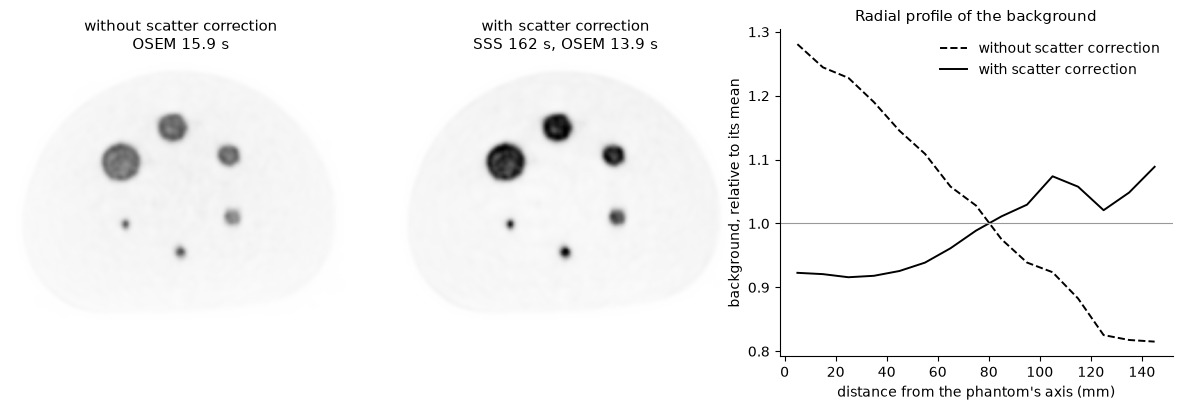

In [12]:
aspect = (y1 - y0) * dy / ((x1 - x0) * dx)  # of the transverse views
fig = plt.figure(figsize=(15, 4.6 * aspect + 0.6), facecolor='white')
grid = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1.15], wspace=0.12)
vmax = np.percentile(images['with'][:, :, k][body[:, :, k]], 99.9) / images['with'][background].mean()
titles = {'without': f'without scatter correction\nOSEM {seconds_without:.1f} s',
          'with': f'with scatter correction\nSSS {seconds_sss:.0f} s, OSEM {seconds_with:.1f} s'}
for n, (name, img) in enumerate(images.items()):
    ax = fig.add_subplot(grid[0, n])
    ax.imshow(img[x0:x1, y0:y1, k].T / img[background].mean(), cmap='Greys', vmin=0, vmax=vmax,
              interpolation='gaussian')
    ax.set_title(titles[name], fontsize=11)
    ax.axis('off')
ax = fig.add_subplot(grid[0, 2])
for name, style in (('without', '--'), ('with', '-')):
    ax.plot(*profiles[name], style, color='k', lw=1.4, label=f'{name} scatter correction')
ax.axhline(1, color='0.6', lw=0.8)
ax.set_xlabel("distance from the phantom's axis (mm)")
ax.set_ylabel('background, relative to its mean')
ax.set_title('Radial profile of the background', fontsize=11)
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

**The background is not quite flat yet.** With scatter correction, the middle of the phantom is still about 8% below the background's mean and its edge about 9% above it, as the profile shows. The cause is not known yet: the scatter estimate's shape through the phantom, or a radial error in this scanner's normalisation or attenuation map. Finding which is planned for v4.1. On simulated data, whose true scatter is known, the [GATE list mode tutorial](t_PETGATE_scat_lm.ipynb) compares the scatter estimate with it.

## 6. Save the images

`io.save_dicom` writes each reconstruction as a DICOM PET series, one file per slice, where `object_meta` places it: centred on the scanner, along the patient's axes. The attenuation map, an input rather than a reconstruction, stays in NIfTI (`io.save_nifti`), in the same place, in 1/mm.

In [13]:
for name, image in [('osem_with_scatter_correction', recon_with_scatter),
                    ('osem_without_scatter_correction', recon_without_scatter)]:
    io.save_dicom(image, OUTPUT / 't_PETSIRD' / name, object_meta, series_description=name.replace('_', ' '),
                  overwrite=True)
io.save_nifti(attenuation_map, OUTPUT / 't_PETSIRD' / 'attenuation_map.nii.gz', object_meta, units='1/mm')

WindowsPath('C:/v4runs/laptop/outputs-r1/PET/PETSIRD-mMR-NEMA/t_PETSIRD/attenuation_map.nii.gz')

## Next steps

- `MINUTES = 10` reconstructs the first 10 minutes, 38 million prompts, in about 4 GB less RAM and with more noise. Most of the memory is the scanner's normalisation and the scatter estimate's sinograms, which don't depend on the scan's length.
- Scanners with time of flight: `io.PET.read_petsird` adds each event's TOF bin as a third column, and gives the TOF bins in `proj_meta.tof_meta`, which `PETLMProjMeta` and the scatter estimate take, as in the [GATE TOF list mode tutorial](t_PETGATE_scat_lmTOF.ipynb).

In [14]:

import json, platform, torch, pytomography
def _peak_ram_gb():
    try:
        import psutil
        m = psutil.Process().memory_info()
        if hasattr(m, "peak_pagefile"):  # Windows: peak committed memory
            return round(m.peak_pagefile / 1e9, 1)
    except ImportError:
        pass
    import resource  # ru_maxrss is in kB on Linux, bytes on macOS
    return round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / (1e9 if platform.system() == "Darwin" else 1e6), 1)
_info = dict(pytomography=getattr(pytomography, "__version__", "?"), source=pytomography.__file__,
             torch=torch.__version__, python=platform.python_version(),
             gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
             peak_gpu_gb=round(torch.cuda.max_memory_allocated() / 1e9, 2) if torch.cuda.is_available() else 0.0,
             peak_ram_gb=_peak_ram_gb())
print("__PYTOMOGRAPHY_RUN__" + json.dumps(_info))


__PYTOMOGRAPHY_RUN__{"pytomography": "4.0.0rc1", "source": "C:\\Users\\lukep\\miniforge3\\envs\\pytomo-rc1\\Lib\\site-packages\\pytomography\\__init__.py", "torch": "2.14.1+cu130", "python": "3.12.16", "gpu": "NVIDIA GeForce RTX 5060 Laptop GPU", "peak_gpu_gb": 5.98, "peak_ram_gb": 21.8}
